# Workshop-3 — Paso 1: Análisis Exploratorio de Datos (EDA)

**Curso:** ETL (G01) — **Datos:** World Happiness Report 2015 a 2019 (5 archivos CSV)

**Qué pide el taller en este paso:** analizar valores faltantes, registros duplicados, nombres de columnas inconsistentes, tipos de datos inconsistentes, diferencias de esquema entre años y posibles valores atípicos.

**Entregables de este notebook:**
1. El EDA (este notebook).
2. Observaciones de calidad de datos (sección 8).
3. Propuesta de esquema unificado (sección 9).

> En este notebook **solo se observa**; no se modifica ningún archivo. La limpieza se hace en el Paso 2.

## 1. Cargar los 5 archivos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW = "../data/raw"
YEARS = [2015, 2016, 2017, 2018, 2019]

# Un diccionario: la llave es el año y el valor es la tabla de ese año
dfs = {year: pd.read_csv(f"{RAW}/{year}.csv") for year in YEARS}

for year, df in dfs.items():
    print(year, "->", df.shape[0], "filas,", df.shape[1], "columnas")

2015 -> 158 filas, 12 columnas
2016 -> 157 filas, 13 columnas
2017 -> 155 filas, 12 columnas
2018 -> 156 filas, 9 columnas
2019 -> 156 filas, 9 columnas


## 2. Diferencias de esquema entre años

Primero se listan las columnas de cada archivo para ver si se llaman igual.

In [2]:
for year, df in dfs.items():
    print(f"--- {year} ({df.shape[1]} columnas) ---")
    for col in df.columns:
        print("   ", col)

--- 2015 (12 columnas) ---
    Country
    Region
    Happiness Rank
    Happiness Score
    Standard Error
    Economy (GDP per Capita)
    Family
    Health (Life Expectancy)
    Freedom
    Trust (Government Corruption)
    Generosity
    Dystopia Residual
--- 2016 (13 columnas) ---
    Country
    Region
    Happiness Rank
    Happiness Score
    Lower Confidence Interval
    Upper Confidence Interval
    Economy (GDP per Capita)
    Family
    Health (Life Expectancy)
    Freedom
    Trust (Government Corruption)
    Generosity
    Dystopia Residual
--- 2017 (12 columnas) ---
    Country
    Happiness.Rank
    Happiness.Score
    Whisker.high
    Whisker.low
    Economy..GDP.per.Capita.
    Family
    Health..Life.Expectancy.
    Freedom
    Generosity
    Trust..Government.Corruption.
    Dystopia.Residual
--- 2018 (9 columnas) ---
    Overall rank
    Country or region
    Score
    GDP per capita
    Social support
    Healthy life expectancy
    Freedom to make life choices
  

**Lo que se ve:** hay tres "familias" de esquema.

| Años | Estilo de nombres | Ejemplo |
|---|---|---|
| 2015 y 2016 | Con espacios y paréntesis | `Economy (GDP per Capita)` |
| 2017 | Con puntos | `Economy..GDP.per.Capita.` |
| 2018 y 2019 | Nombres distintos y más cortos | `GDP per capita` |

La siguiente tabla muestra, para cada concepto, cómo se llama la columna en cada año. Un `-` significa que ese año no trae esa columna.

In [3]:
# Para cada concepto: palabra clave que identifica su columna en cualquier año
conceptos = {
    "país":            ["Country"],
    "región":          ["Region"],
    "ranking":         ["Rank", "rank"],
    "puntaje":         ["Score"],
    "PIB":             ["GDP"],
    "apoyo social":    ["Family", "Social support"],
    "salud":           ["Health", "Healthy"],
    "libertad":        ["Freedom"],
    "generosidad":     ["Generosity"],
    "corrupción":      ["Trust", "corruption"],
    "residuo distopía":["Dystopia"],
}

def buscar(df, claves):
    for col in df.columns:
        if col == "Country or region" and claves == ["Region"]:
            continue  # esta columna es el país, no la región
        if any(c in col for c in claves):
            return col
    return "-"

comparacion = pd.DataFrame(
    {year: {nombre: buscar(df, claves) for nombre, claves in conceptos.items()}
     for year, df in dfs.items()}
)
comparacion

,2015,2016,2017,2018,2019
país,Country,Country,Country,Country or region,Country or region
región,Region,Region,-,-,-
ranking,Happiness Rank,Happiness Rank,Happiness.Rank,Overall rank,Overall rank
puntaje,Happiness Score,Happiness Score,Happiness.Score,Score,Score
PIB,Economy (GDP per Capita),Economy (GDP per Capita),Economy..GDP.per.Capita.,GDP per capita,GDP per capita
apoyo social,Family,Family,Family,Social support,Social support
salud,Health (Life Expectancy),Health (Life Expectancy),Health..Life.Expectancy.,Healthy life expectancy,Healthy life expectancy
libertad,Freedom,Freedom,Freedom,Freedom to make life choices,Freedom to make life choices
generosidad,Generosity,Generosity,Generosity,Generosity,Generosity
corrupción,Trust (Government Corruption),Trust (Government Corruption),Trust..Government.Corruption.,Perceptions of corruption,Perceptions of corruption


**Columnas que solo existen en algunos años** (no sirven para un esquema común):

- `Region`: solo 2015 y 2016.
- `Standard Error`: solo 2015.
- `Lower/Upper Confidence Interval`: solo 2016.
- `Whisker.high` / `Whisker.low`: solo 2017.
- `Dystopia Residual`: 2015 a 2017.

Además, **ningún archivo trae una columna de año**: el año solo está en el nombre del archivo.

## 3. Tipos de datos

In [4]:
tipos = pd.DataFrame({year: df.dtypes.astype(str).value_counts() for year, df in dfs.items()}).fillna(0).astype(int)
tipos

,2015,2016,2017,2018,2019
float64,9,10,10,7,7
int64,1,1,1,1,1
str,2,2,1,1,1


In [5]:
# ¿Qué columnas son texto en cada año?
for year, df in dfs.items():
    print(year, "-> columnas de texto:", list(df.select_dtypes(exclude="number").columns))

2015 -> columnas de texto: ['Country', 'Region']
2016 -> columnas de texto: ['Country', 'Region']
2017 -> columnas de texto: ['Country']
2018 -> columnas de texto: ['Country or region']
2019 -> columnas de texto: ['Country or region']


**Lo que se ve:** los indicadores numéricos quedan como números en los 5 archivos; las únicas columnas de texto son el país y la región. No hay números guardados como texto.

Una diferencia de formato: 2017 trae los números con muchos decimales (por ejemplo `7.53700017929077`) y los demás años con 3 a 5 decimales.

In [6]:
# Primeros puntajes de 2017 y de 2019, tal como vienen en el archivo
print("2017:", dfs[2017]["Happiness.Score"].head(3).tolist())
print("2019:", dfs[2019]["Score"].head(3).tolist())

2017: [7.53700017929077, 7.52199983596802, 7.50400018692017]
2019: [7.769, 7.6, 7.554]


## 4. Valores faltantes

In [7]:
faltantes = pd.DataFrame({year: df.isna().sum().sum() for year, df in dfs.items()}, index=["celdas vacías"])
faltantes

,2015,2016,2017,2018,2019
celdas vacías,0,0,0,1,0


In [8]:
# ¿Dónde está el faltante de 2018?
dfs[2018][dfs[2018].isna().any(axis=1)]

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN


**Lo que se ve:** en los 5 archivos solo hay **1 celda vacía**: `Perceptions of corruption` de **United Arab Emirates en 2018**.

## 5. Registros duplicados

Se revisan dos cosas: filas completamente repetidas y países repetidos dentro de un mismo año.

In [9]:
duplicados = pd.DataFrame({
    year: {
        "filas repetidas": df.duplicated().sum(),
        "países repetidos": df[buscar(df, ["Country"])].duplicated().sum(),
    }
    for year, df in dfs.items()
})
duplicados

,2015,2016,2017,2018,2019
filas repetidas,0,0,0,0,0
países repetidos,0,0,0,0,0


**Lo que se ve:** no hay duplicados en ningún año. Cada país aparece una sola vez por archivo.

## 6. Consistencia de los nombres de países

Como el país va a ser la clave del evento en Kafka y una dimensión en la base de datos, importa que el mismo país se escriba igual todos los años.

In [10]:
paises = {year: set(df[buscar(df, ["Country"])]) for year, df in dfs.items()}
todos = set.union(*paises.values())
en_los_5 = set.intersection(*paises.values())

print("Países distintos en total:", len(todos))
print("Países presentes en los 5 años:", len(en_los_5))

# Países que faltan en al menos un año, y en qué años aparecen
presencia = pd.DataFrame(
    {year: ["x" if p in paises[year] else "" for p in sorted(todos - en_los_5)] for year in YEARS},
    index=sorted(todos - en_los_5),
)
presencia

Países distintos en total: 170
Países presentes en los 5 años: 141


,2015,2016,2017,2018,2019
Angola,x,x,x,x,
Belize,,x,x,x,
Central African Republic,x,,x,x,x
Comoros,x,x,,,x
Djibouti,x,,,,
Gambia,,,,,x
Hong Kong,x,x,,x,x
"Hong Kong S.A.R., China",,,x,,
Laos,x,x,,x,x
Lesotho,x,,x,x,x


**Lo que se ve:** hay dos situaciones distintas mezcladas en esa tabla.

**a) El mismo país escrito de formas diferentes** (hay que unificarlo en el Paso 2):

| Variantes encontradas | Nombre propuesto |
|---|---|
| `Hong Kong` / `Hong Kong S.A.R., China` | Hong Kong |
| `Taiwan` / `Taiwan Province of China` | Taiwan |
| `Trinidad and Tobago` / `Trinidad & Tobago` | Trinidad and Tobago |
| `North Cyprus` / `Northern Cyprus` | Northern Cyprus |
| `Macedonia` / `North Macedonia` | North Macedonia |
| `Somaliland region` / `Somaliland Region` | Somaliland Region |

**b) Países que de verdad no fueron medidos todos los años** (por ejemplo Oman, Puerto Rico, Belize, Angola). Eso no es un error: es cobertura distinta de la encuesta y se deja tal cual.

## 7. Rangos y posibles valores atípicos

Para comparar los años se arma una **vista temporal** con nombres comunes. Es solo para este análisis; la unificación definitiva se hace en el Paso 2.

In [11]:
mapa = {
    "puntaje": "happiness_score", "PIB": "gdp", "apoyo social": "family",
    "salud": "health", "libertad": "freedom", "generosidad": "generosity", "corrupción": "corruption",
}

partes = []
for year, df in dfs.items():
    columnas = {comparacion.loc[concepto, year]: nuevo for concepto, nuevo in mapa.items()}
    parte = df[list(columnas)].rename(columns=columnas)
    parte.insert(0, "year", year)
    parte.insert(0, "country", df[buscar(df, ["Country"])])
    partes.append(parte)

vista = pd.concat(partes, ignore_index=True)
print(vista.shape)
vista.describe().round(3)

(782, 9)


,year,happiness_score,gdp,family,health,freedom,generosity,corruption
count,782.000,782.000,782.000,782.000,782.000,782.000,782.000,781.000
mean,2016.994,5.379,0.916,1.078,0.612,0.411,0.219,0.125
std,1.417,1.127,0.407,0.330,0.248,0.153,0.122,0.106
min,2015.000,2.693,0.000,0.000,0.000,0.000,0.000,0.000
25%,2016.000,4.510,0.606,0.869,0.440,0.310,0.130,0.054
50%,2017.000,5.322,0.982,1.125,0.647,0.431,0.202,0.091
75%,2018.000,6.190,1.236,1.327,0.808,0.531,0.279,0.156
max,2019.000,7.769,2.096,1.644,1.141,0.724,0.838,0.552


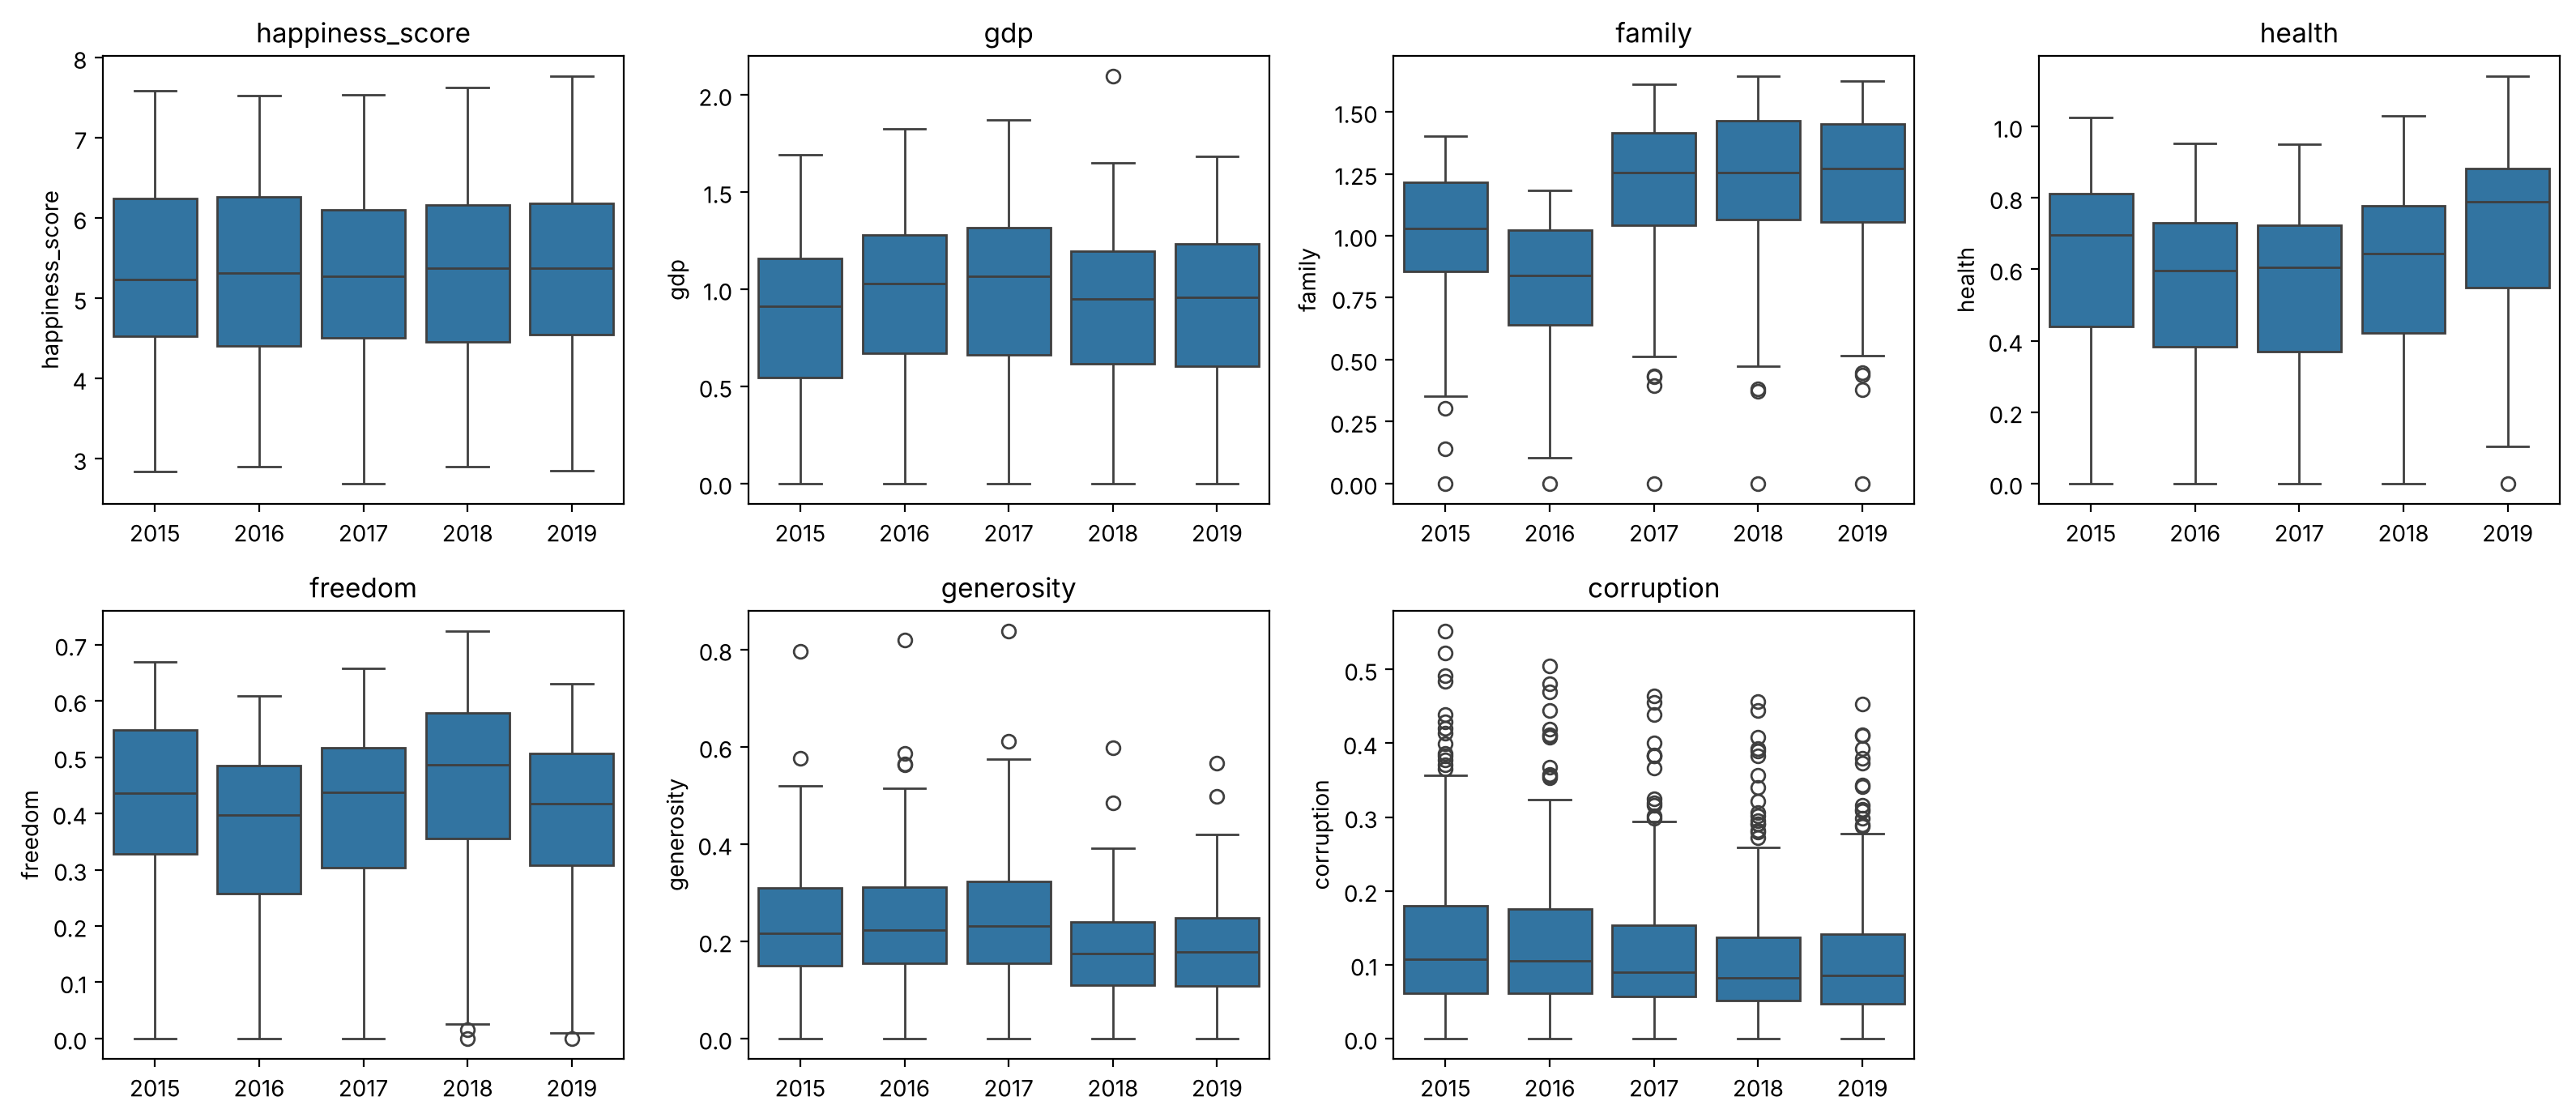

In [12]:
numericas = list(mapa.values())

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), numericas):
    sns.boxplot(data=vista, x="year", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Regla del rango intercuartílico (IQR): un valor es atípico si está
# a más de 1.5 veces el IQR por debajo de Q1 o por encima de Q3.
conteo = {}
for col in numericas:
    q1, q3 = vista[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = (vista[col] < q1 - 1.5 * iqr) | (vista[col] > q3 + 1.5 * iqr)
    conteo[col] = fuera.sum()

pd.Series(conteo, name="valores atípicos (IQR)").to_frame()

,valores atípicos (IQR)
happiness_score,0
gdp,0
family,10
health,0
freedom,0
generosity,17
corruption,67


In [14]:
# Valores negativos y ceros exactos
print("Valores negativos:", (vista[numericas] < 0).sum().sum())
print()
print("Ceros exactos por columna:")
print((vista[numericas] == 0).sum())

Valores negativos: 0

Ceros exactos por columna:
happiness_score    0
gdp                5
family             5
health             5
freedom            5
generosity         5
corruption         6
dtype: int64


In [15]:
# ¿Qué registros tienen ceros?
vista[(vista[numericas] == 0).any(axis=1)].sort_values(["year", "country"])

,country,year,happiness_score,gdp,family,health,freedom,generosity,corruption
147,Central African Republic,2015,3.678,0.078500,0.000000,0.066990,0.488790,0.238350,0.082890
119,Congo (Kinshasa),2015,4.517,0.000000,1.001200,0.098060,0.226050,0.248340,0.076250
101,Greece,2015,4.857,1.154060,0.929330,0.882130,0.076990,0.000000,0.013970
73,Indonesia,2015,5.399,0.828270,1.087080,0.637930,0.466110,0.515350,0.000000
111,Iraq,2015,4.677,0.985490,0.818890,0.602370,0.000000,0.179220,0.137880
122,Sierra Leone,2015,4.507,0.330240,0.955710,0.000000,0.408400,0.214880,0.087860
244,Bosnia and Herzegovina,2016,5.163,0.933830,0.643670,0.707660,0.095110,0.298890,0.000000
256,Greece,2016,5.033,1.248860,0.754730,0.800290,0.058220,0.000000,0.041270
268,Sierra Leone,2016,4.635,0.364850,0.628000,0.000000,0.306850,0.238970,0.081960
233,Somalia,2016,5.440,0.000000,0.336130,0.114660,0.567780,0.272250,0.311800


**Lo que se ve:**

- No hay valores negativos ni puntajes fuera de la escala esperada (el puntaje va de 2.7 a 7.8 aproximadamente).
- Los valores atípicos se concentran en `corruption` (67), `generosity` (17) y `family` (10). Son países reales con valores extremos (por ejemplo, unos pocos países con un indicador de corrupción mucho más alto que el resto), no errores de digitación.
- Hay **31 ceros exactos** entre 782 filas. Corresponden al país con el valor más bajo de ese indicador en ese año, porque el informe mide cada factor respecto a un mínimo de referencia. Son datos válidos, no faltantes disfrazados.

## 8. Observaciones de calidad de datos

| # | Aspecto revisado | Hallazgo | Qué se hará en el Paso 2 |
|---|---|---|---|
| 1 | Nombres de columnas | 3 estilos distintos para los mismos conceptos | Renombrar todo a un esquema único |
| 2 | Diferencias de esquema | Entre 9 y 13 columnas según el año; varias columnas existen solo en algunos años | Conservar solo las columnas comunes a los 5 años |
| 3 | Columna de año | No existe en ningún archivo | Crearla a partir del nombre del archivo |
| 4 | Tipos de datos | Consistentes (números como números); 2017 con exceso de decimales | Redondear a una precisión común |
| 5 | Valores faltantes | 1 celda vacía: corrupción de United Arab Emirates en 2018 | Decidir y justificar su tratamiento |
| 6 | Duplicados | Ninguno | Volver a comprobar después de unir los 5 años |
| 7 | Nombres de países | 6 países escritos de dos formas | Unificar a un solo nombre |
| 8 | Valores atípicos | Presentes en corrupción, generosidad y apoyo social; son valores reales | Conservarlos |
| 9 | Ceros exactos | 31 casos; son el mínimo del indicador | Conservarlos |

## 9. Propuesta de esquema unificado

Los nombres se eligieron para que coincidan con el formato JSON que exige el taller para los eventos de Kafka (`gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`).

| Columna unificada | Tipo | 2015 / 2016 | 2017 | 2018 / 2019 |
|---|---|---|---|---|
| `country` | texto | Country | Country | Country or region |
| `year` | entero | (nombre del archivo) | (nombre del archivo) | (nombre del archivo) |
| `gdp` | decimal | Economy (GDP per Capita) | Economy..GDP.per.Capita. | GDP per capita |
| `family` | decimal | Family | Family | Social support |
| `health` | decimal | Health (Life Expectancy) | Health..Life.Expectancy. | Healthy life expectancy |
| `freedom` | decimal | Freedom | Freedom | Freedom to make life choices |
| `generosity` | decimal | Generosity | Generosity | Generosity |
| `corruption` | decimal | Trust (Government Corruption) | Trust..Government.Corruption. | Perceptions of corruption |
| `happiness_score` | decimal | Happiness Score | Happiness.Score | Score |

**Columnas que se descartan y por qué:**

- `Happiness Rank` / `Overall rank`: se calcula a partir del puntaje. Usarlo para predecir el puntaje sería **fuga del objetivo** (*target leakage*).
- `Dystopia Residual`: es la parte del puntaje que no explican los 6 factores, es decir, también se deriva del puntaje (fuga del objetivo). Además no existe en 2018 ni 2019.
- `Standard Error`, intervalos de confianza y `Whisker`: describen la incertidumbre del puntaje, existen solo en un año cada uno y no son características del país.
- `Region`: solo existe en 2015 y 2016.

**Tamaño esperado del dataset unificado:** 158 + 157 + 155 + 156 + 156 = **782 filas** y 9 columnas.